# What drives the age young people leave the parental home in the EU? (2016–2024)

**Question.** Which factors move with the average age at which young people leave home, looking at the EU as a whole (no focus on a single country or gender)?

**Candidate factors.** income, living expenses (HICP), house price-to-income ratio, employment rate, young people not in employment/education/training (NEET).

**Design.** 27 countries × 9 years = 243 country-years, treated as one EU panel. The unweighted EU mean/median of the leaving age barely moves, so besides levels we look at (a) zoomed axes, (b) year-over-year changes, and (c) deviations from each country's own average. "EU mean/median" always means the **unweighted** mean/median across countries.

Models use standardised predictors (effect = years per +1 SD) and standard errors clustered by country.

## 0. Setup and data

In [1]:
suppressPackageStartupMessages({
  library(dplyr); library(tidyr); library(ggplot2); library(broom); library(knitr)
})
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
theme_set(theme_minimal(base_size = 12) +
          theme(plot.title = element_text(face = "bold"), legend.position = "bottom"))
fig_dir <- "../figures/eu_drivers_analysis"
dir.create(fig_dir, recursive = TRUE, showWarnings = FALSE)
save_fig <- function(p, name, w = 10, h = 6) ggsave(file.path(fig_dir, name), p, width = w, height = h, dpi = 150, bg = "white")
tab <- function(x, d = 2) IRdisplay::display_markdown(paste(knitr::kable(x, digits = d, format = "pipe"), collapse = "\n"))

In [2]:
p <- "../../../data/"
leave <- read.csv(paste0(p, "leaving_home_clean_data.csv"), stringsAsFactors = FALSE)
inc   <- read.csv(paste0(p, "income_clean_data.csv"), stringsAsFactors = FALSE)
hicp  <- read.csv(paste0(p, "hicp_living_expense_clean_data.csv"), stringsAsFactors = FALSE)
neet  <- read.csv(paste0(p, "neet_clean_data.csv"), stringsAsFactors = FALSE)

d <- leave %>%
  select(country, year, leave_age = leave_age_total, price_income = price_income_ratio,
         employment = employment_rate_20_64) %>%
  inner_join(inc  %>% select(country, year, income = median_equiv_income_pps), by = c("country", "year")) %>%
  inner_join(hicp %>% select(country, year, hicp = hicp_all_index),            by = c("country", "year")) %>%
  inner_join(neet %>% select(country, year, neet = neet_total),                by = c("country", "year")) %>%
  mutate(log_income = log(income)) %>%
  arrange(country, year)

cat("Rows x cols:", dim(d), "| countries:", n_distinct(d$country), "| years:", range(d$year), "\n")
cat("Missing values:", sum(is.na(d)), "| balanced (9 obs per country):", all(table(d$country) == 9), "\n")
tab(d %>% select(leave_age, income, hicp, price_income, employment, neet) %>%
      pivot_longer(everything()) %>% group_by(variable = name) %>%
      summarise(mean = mean(value), sd = sd(value), min = min(value), median = median(value), max = max(value)))

Rows x cols: 243 9 | countries: 27 | years: 2016 2024 


Missing values: 0 | balanced (9 obs per country): TRUE 


|variable     |     mean|      sd|     min|   median|      max|
|:------------|--------:|-------:|-------:|--------:|--------:|
|employment   |    74.32|    5.68|   55.90|    75.40|    83.50|
|hicp         |   112.35|   13.71|   98.68|   106.96|   166.56|
|income       | 16975.51| 6010.03| 4724.00| 16988.00| 37781.00|
|leave_age    |    26.66|    3.13|   17.50|    26.90|    33.40|
|neet         |    11.87|    4.09|    3.90|    11.00|    24.30|
|price_income |    98.63|   13.81|   48.23|    97.32|   152.06|

Four clean files are merged on `country, year`. Income = median equivalised income in PPS (modelled in logs); living expenses = HICP all-items index (cumulative price level, not the rate); NEET = total NEET rate for ages 15–29. The panel is balanced with no missing values.

## 1. The EU trend of the leaving age

| year|   mean| median|   p25|   p75|
|----:|------:|------:|-----:|-----:|
| 2016| 26.700|   27.2| 24.60| 29.05|
| 2017| 26.615|   27.0| 23.90| 29.00|
| 2018| 26.511|   26.6| 24.45| 29.05|
| 2019| 26.419|   26.8| 24.45| 28.90|
| 2020| 26.641|   26.9| 24.90| 29.70|
| 2021| 27.033|   27.4| 24.50| 29.75|
| 2022| 26.837|   26.9| 24.25| 29.70|
| 2023| 26.693|   27.1| 24.05| 29.05|
| 2024| 26.467|   26.8| 23.75| 28.55|

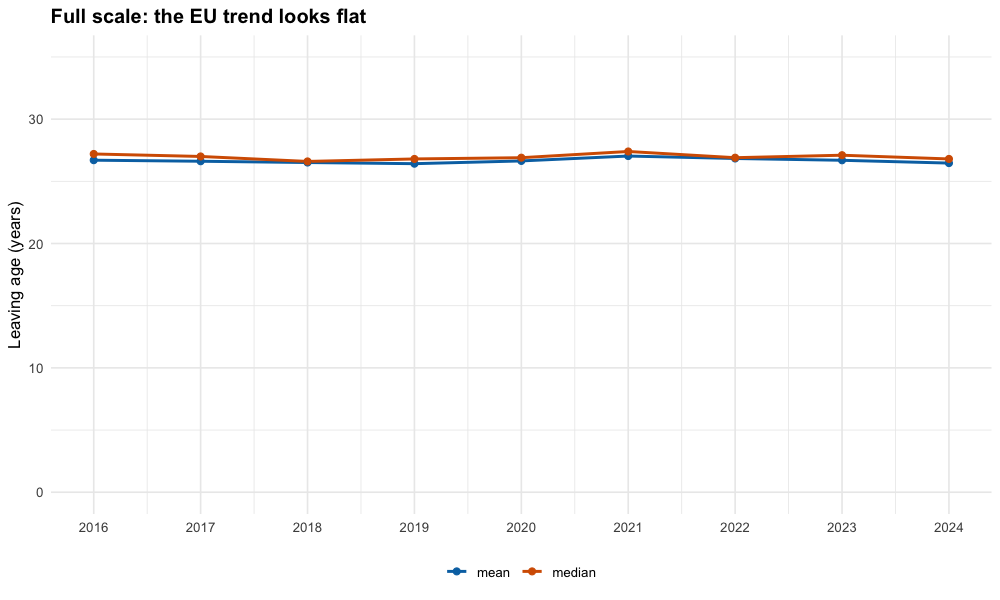

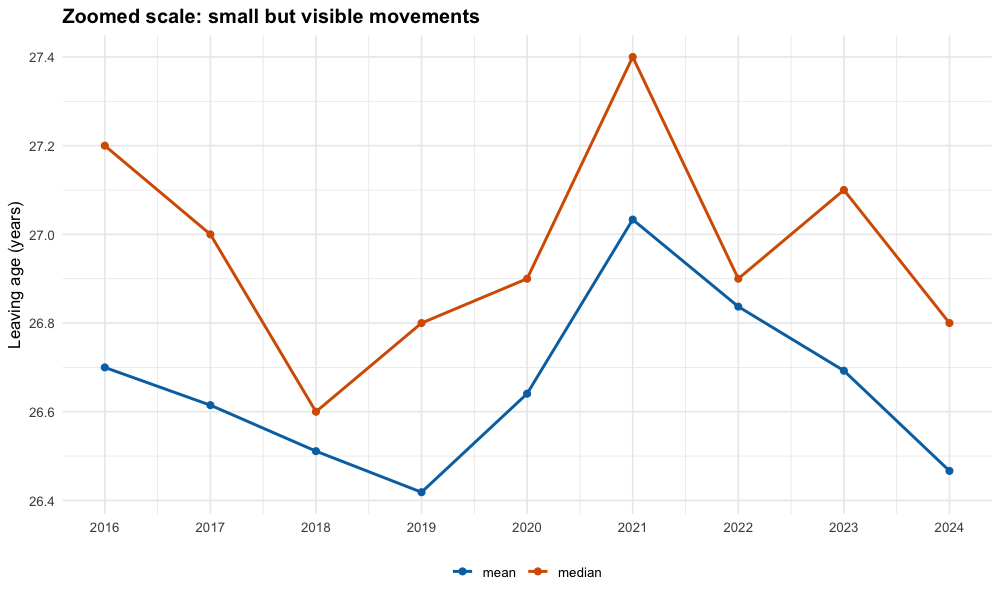

In [3]:
eu <- d %>% group_by(year) %>%
  summarise(mean = mean(leave_age), median = median(leave_age), p25 = quantile(leave_age, .25), p75 = quantile(leave_age, .75))
tab(eu, 3)
eu_l <- eu %>% select(year, mean, median) %>% pivot_longer(-year, names_to = "stat")
base <- ggplot(eu_l, aes(year, value, colour = stat)) + geom_line(linewidth = 1) + geom_point(size = 2) +
  scale_x_continuous(breaks = 2016:2024) + scale_colour_manual(values = c(mean = "#0072B2", median = "#D55E00"), name = NULL) +
  labs(x = NULL, y = "Leaving age (years)")
p1 <- base + ylim(0, 35) + labs(title = "Full scale: the EU trend looks flat")
p2 <- base + labs(title = "Zoomed scale: small but visible movements")
print(p1); print(p2)
save_fig(p1, "01a_eu_trend_full.png", 8, 5)
save_fig(p2, "01b_eu_trend_zoom.png", 8, 5)

**Findings**

- On the full scale the EU mean (26.4–27.0) and median (26.6–27.4) look flat; on the zoomed scale there is a small but clear pattern: a decline 2016→2019 (26.70→26.42), a jump in 2021 (27.03) and a decline afterwards to 26.47 in 2024.
- The overall change 2016→2024 is only −0.23 years for the mean, so differences of a few tenths of a year are what any factor has to explain.
- The 2021 bump is partly driven by two country series: Sweden (17.5→22.0, a break in the series) and Portugal (29.9→33.3→30.1). Together they contribute roughly 0.3 of the 0.39-year rise in the mean, which is why sensitivity checks below exclude them.

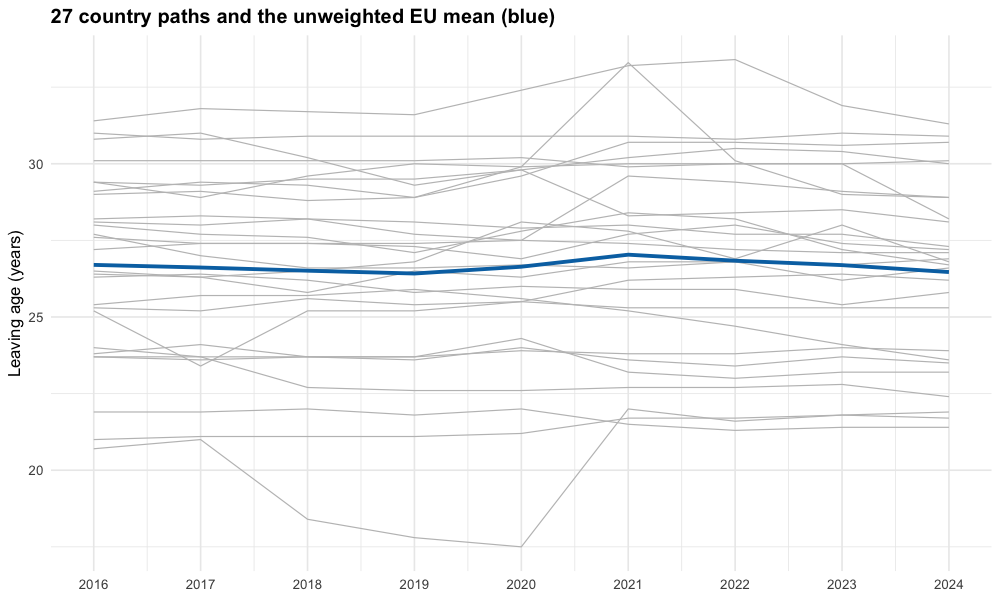

In [4]:
p <- ggplot(d, aes(year, leave_age, group = country)) +
  geom_line(colour = "grey75", linewidth = .4) +
  geom_line(data = eu, aes(y = mean, group = 1), colour = "#0072B2", linewidth = 1.3) +
  scale_x_continuous(breaks = 2016:2024) +
  labs(title = "27 country paths and the unweighted EU mean (blue)", x = NULL, y = "Leaving age (years)")
print(p); save_fig(p, "01c_country_paths.png")

The country paths are widely spread (about 17–33 years) while the EU mean moves by tenths of a year: the **level** differences are between countries, and the **time** movement is small.

## 2. Smaller-scale view: changes and within-country deviations

`d_*` = year-over-year change (216 rows); `w_*` = deviation from the country's own 2016–24 mean.

Rows in first-difference data: 216 (expected 27 x 8 = 216)


| year| d_leave_age| d_log_income| d_hicp| d_price_income| d_employment| d_neet|
|----:|-----------:|------------:|------:|--------------:|------------:|------:|
| 2017|      -0.085|        0.015|  1.709|          1.239|        1.544| -0.941|
| 2018|      -0.104|        0.029|  1.939|          0.350|        1.359| -0.763|
| 2019|      -0.093|        0.054|  1.761|          0.733|        0.919| -0.396|
| 2020|       0.222|        0.015|  0.742|          3.035|       -0.959|  1.104|
| 2021|       0.393|        0.030|  3.045|          2.304|        1.222| -0.741|
| 2022|      -0.196|        0.053| 11.853|          2.073|        1.767| -1.115|
| 2023|      -0.144|        0.053|  8.614|         -5.769|        0.485| -0.233|
| 2024|      -0.226|        0.077|  3.463|         -1.669|        0.478| -0.130|

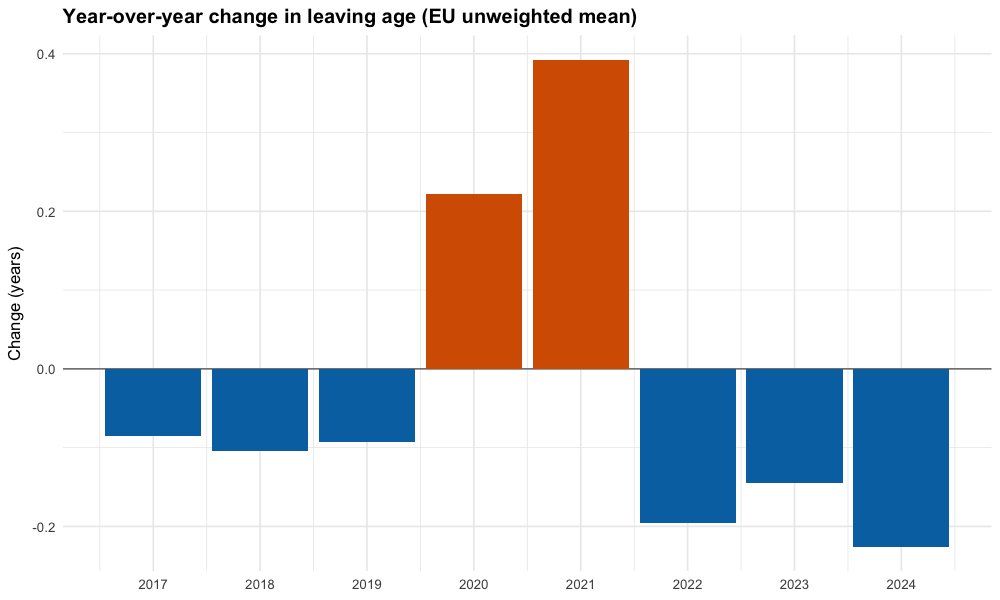

In [5]:
vars <- c("leave_age", "log_income", "hicp", "price_income", "employment", "neet")
d <- d %>% group_by(country) %>%
  mutate(across(all_of(vars), ~ . - dplyr::lag(.), .names = "d_{.col}"),
         across(all_of(vars), ~ . - mean(.), .names = "w_{.col}")) %>% ungroup()
dd <- d %>% filter(year > 2016)
cat("Rows in first-difference data:", nrow(dd), "(expected 27 x 8 = 216)\n")
yoy <- dd %>% group_by(year) %>% summarise(across(starts_with("d_"), mean))
tab(yoy %>% select(year, d_leave_age, d_log_income, d_hicp, d_price_income, d_employment, d_neet), 3)
p <- ggplot(yoy, aes(year, d_leave_age)) + geom_hline(yintercept = 0, colour = "grey50") +
  geom_col(aes(fill = d_leave_age > 0), show.legend = FALSE) +
  scale_fill_manual(values = c("TRUE" = "#D55E00", "FALSE" = "#0072B2")) + scale_x_continuous(breaks = 2017:2024) +
  labs(title = "Year-over-year change in leaving age (EU unweighted mean)", x = NULL, y = "Change (years)")
print(p); save_fig(p, "02_yoy_change.png", 8, 5)

**Findings**

- The EU-average change in leaving age is within ±0.4 years each year: −0.09 to −0.10 in 2017–19, +0.22 in 2020, +0.39 in 2021, then −0.14 to −0.23 in 2022–24.
- In the same years income grew steadily (+1.5% to +7.7% a year), employment rose except 2020, NEET fell except 2020, and HICP accelerated sharply in 2022–23 (+11.9 and +8.6 index points). 2020–21 is the only period where leaving age rose, coinciding with the pandemic, higher NEET and a jump in the price-to-income ratio.

## 3. EU trends of the candidate factors

|name                            |     2016|     2024|  change|
|:-------------------------------|--------:|--------:|-------:|
|Median equivalised income (PPS) | 15149.81| 20187.04| 5037.22|
|HICP index (living expenses)    |   100.14|   133.26|   33.13|
|House price-to-income ratio     |    94.84|    97.13|    2.30|
|Employment rate 20-64 (%)       |    70.52|    77.33|    6.81|
|NEET rate 15-29 (%)             |    13.72|    10.51|   -3.21|
|Leaving age (years)             |    26.70|    26.47|   -0.23|

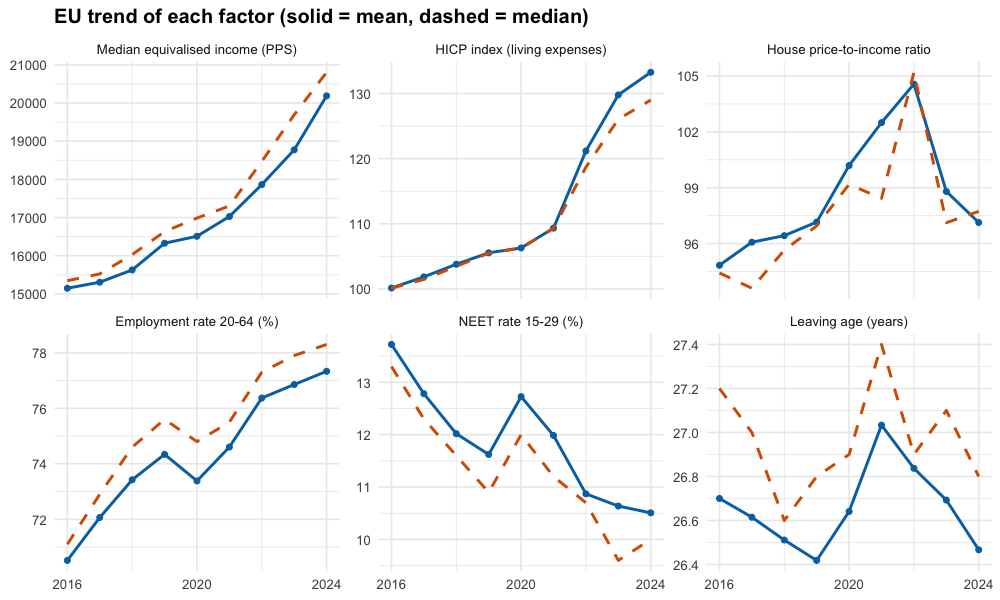

In [6]:
lab <- c(income = "Median equivalised income (PPS)", hicp = "HICP index (living expenses)",
         price_income = "House price-to-income ratio", employment = "Employment rate 20-64 (%)",
         neet = "NEET rate 15-29 (%)", leave_age = "Leaving age (years)")
ft <- d %>% select(country, year, leave_age, income, hicp, price_income, employment, neet) %>%
  pivot_longer(-c(country, year)) %>% group_by(name, year) %>% summarise(mean = mean(value), median = median(value), .groups = "drop") %>%
  mutate(name = factor(lab[name], levels = lab))
p <- ggplot(ft, aes(year, mean)) + geom_line(colour = "#0072B2", linewidth = 1) + geom_point(colour = "#0072B2") +
  geom_line(aes(y = median), colour = "#D55E00", linewidth = 1, linetype = 2) +
  facet_wrap(~name, scales = "free_y") + scale_x_continuous(breaks = c(2016, 2020, 2024)) +
  labs(title = "EU trend of each factor (solid = mean, dashed = median)", x = NULL, y = NULL)
print(p); save_fig(p, "03_factor_trends.png", 11, 6)
tab(ft %>% group_by(name) %>% summarise(`2016` = mean[year == 2016], `2024` = mean[year == 2024], change = `2024` - `2016`))

**Findings**

- 2016→2024 (unweighted EU mean): income +5,037 PPS (≈ +33%), HICP +33 points, price-to-income ratio +2.3, employment +6.8 pp, NEET −3.2 pp, leaving age −0.23 years.
- Economic conditions improved clearly for young people (more jobs, fewer NEET), while the leaving age fell only slightly: the link is weak at the EU-average level.

## 4. Association with the leaving age

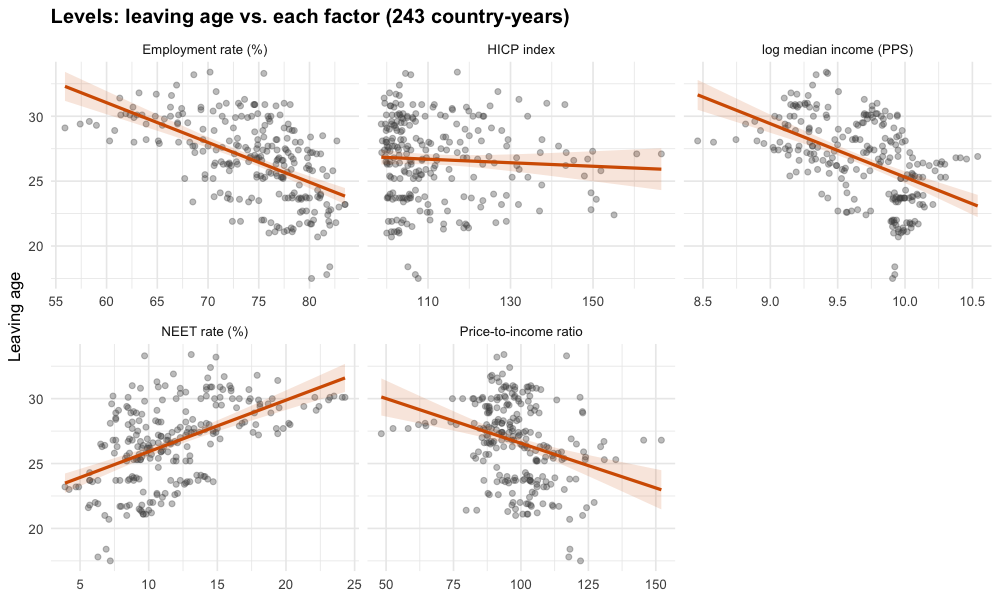

In [7]:
pred <- c("log_income", "hicp", "price_income", "employment", "neet")
plab <- c(log_income = "log median income (PPS)", hicp = "HICP index", price_income = "Price-to-income ratio",
          employment = "Employment rate (%)", neet = "NEET rate (%)")
long_lvl <- d %>% select(leave_age, all_of(pred)) %>% pivot_longer(-leave_age, names_to = "x") %>% mutate(x = plab[x])
p <- ggplot(long_lvl, aes(value, leave_age)) + geom_point(alpha = .35, colour = "grey30") +
  geom_smooth(method = "lm", formula = y ~ x, colour = "#D55E00", fill = "#D55E00", alpha = .15) +
  facet_wrap(~x, scales = "free_x") + labs(title = "Levels: leaving age vs. each factor (243 country-years)", x = NULL, y = "Leaving age")
print(p); save_fig(p, "04_scatter_levels.png", 11, 6)

Between countries (levels), higher income and employment go with an earlier departure, and higher NEET with a later one. The price-to-income ratio is slightly negative and HICP is flat.

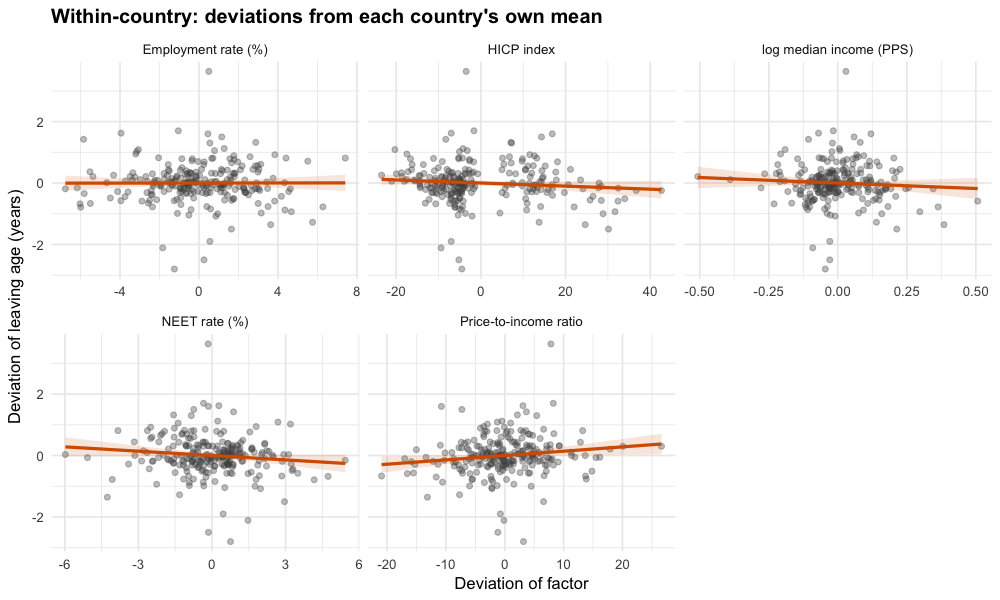

In [8]:
long_w <- d %>% select(starts_with("w_")) %>%
  pivot_longer(-w_leave_age, names_to = "x") %>% mutate(x = plab[sub("^w_", "", x)])
p <- ggplot(long_w, aes(value, w_leave_age)) + geom_point(alpha = .35, colour = "grey30") +
  geom_smooth(method = "lm", formula = y ~ x, colour = "#D55E00", fill = "#D55E00", alpha = .15) +
  facet_wrap(~x, scales = "free_x") +
  labs(title = "Within-country: deviations from each country's own mean", x = "Deviation of factor", y = "Deviation of leaving age (years)")
print(p); save_fig(p, "05_scatter_within.png", 11, 6)

Within a country, relationships are much weaker and noisy; they are mostly driven by a few series (e.g. Sweden, Portugal).

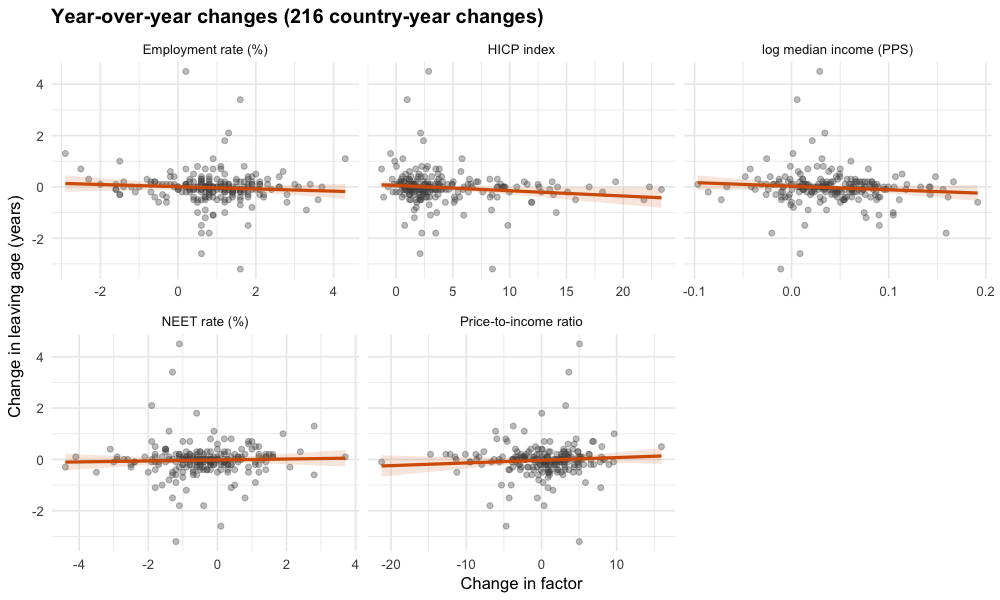

In [9]:
long_d <- dd %>% select(d_leave_age, all_of(paste0("d_", pred))) %>% pivot_longer(-d_leave_age, names_to = "x") %>%
  mutate(x = plab[sub("^d_", "", x)])
p <- ggplot(long_d, aes(value, d_leave_age)) + geom_point(alpha = .35, colour = "grey30") +
  geom_smooth(method = "lm", formula = y ~ x, colour = "#D55E00", fill = "#D55E00", alpha = .15) +
  facet_wrap(~x, scales = "free_x") +
  labs(title = "Year-over-year changes (216 country-year changes)", x = "Change in factor", y = "Change in leaving age (years)")
print(p); save_fig(p, "06_scatter_changes.png", 11, 6)

Year-over-year changes show almost no visible relationship: the fitted lines are near flat, with wide bands.

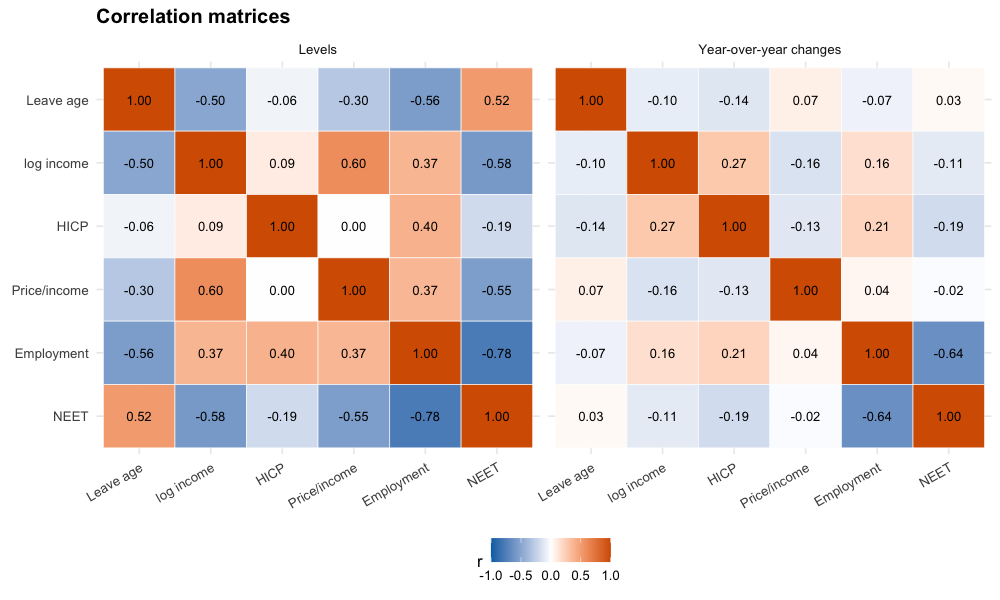

In [10]:
cm <- function(df, cols, nm) {
  m <- cor(df[, cols]); colnames(m) <- rownames(m) <- c("Leave age", "log income", "HICP", "Price/income", "Employment", "NEET")
  as.data.frame(as.table(m)) %>% mutate(set = nm)
}
cors <- bind_rows(cm(d, vars, "Levels"), cm(dd, paste0("d_", vars), "Year-over-year changes"))
cors$Var1 <- factor(cors$Var1, levels = unique(cors$Var1)); cors$Var2 <- factor(cors$Var2, levels = rev(levels(cors$Var1)))
p <- ggplot(cors, aes(Var1, Var2, fill = Freq)) + geom_tile(colour = "white") +
  geom_text(aes(label = sprintf("%.2f", Freq)), size = 3.3) +
  scale_fill_gradient2(low = "#0072B2", mid = "white", high = "#D55E00", limits = c(-1, 1), name = "r") +
  facet_wrap(~set) + labs(title = "Correlation matrices", x = NULL, y = NULL) +
  theme(axis.text.x = element_text(angle = 30, hjust = 1))
print(p); save_fig(p, "07_corr_levels_changes.png", 12, 5.5)

**Findings**

- Levels: leaving age is correlated with employment (−0.56), NEET (+0.52), log income (−0.50) and price-to-income (−0.30); HICP ≈ 0 (−0.06).
- Changes: all correlations with the change in leaving age are small (|r| ≤ 0.14).
- Employment and NEET are strongly collinear (−0.78 in levels, −0.64 in changes), so their separate effects are hard to identify.

### Collinearity check (VIF)

In [11]:
vif_tab <- function(df, cols) sapply(cols, function(v) 1 / (1 - summary(lm(reformulate(setdiff(cols, v), v), df))$r.squared))
tab(data.frame(variable = pred, VIF_levels = vif_tab(d, pred), VIF_changes = vif_tab(dd, paste0("d_", pred))), 2)

|             |variable     | VIF_levels| VIF_changes|
|:------------|:------------|----------:|-----------:|
|log_income   |log_income   |       1.84|        1.11|
|hicp         |hicp         |       1.26|        1.13|
|price_income |price_income |       1.76|        1.04|
|employment   |employment   |       3.17|        1.74|
|neet         |neet         |       3.80|        1.71|

All VIFs are below 4 (highest: NEET 3.8, employment 3.2 in levels), so all five factors can stay in the models, but employment and NEET share information and should be read together.

## 5. Models

- **M1** levels, pooled (between + within variation)
- **M2** levels + country fixed effects (within-country effects only)
- **M3** year-over-year changes
- **M4** changes + year fixed effects (removes EU-wide shocks such as 2020–21)

Effects are in years per +1 SD of the factor. Standard errors are clustered by country (computed manually, CR1 correction, t with 26 df).

In [12]:
z <- function(x) as.numeric(scale(x))
ds  <- d  %>% mutate(across(all_of(pred), z, .names = "z_{.col}"))
dds <- dd %>% mutate(across(all_of(paste0("d_", pred)), z, .names = "z_{.col}"), year_f = factor(year))
zp  <- paste0("z_", pred); zd <- paste0("z_d_", pred)

m1 <- lm(reformulate(zp, "leave_age"), ds)
m2 <- lm(reformulate(c(zp, "factor(country)"), "leave_age"), ds)
m3 <- lm(reformulate(zd, "d_leave_age"), dds)
m4 <- lm(reformulate(c(zd, "year_f"), "d_leave_age"), dds)

# cluster-robust (by country) SEs, CR1 small-sample correction
cl_se <- function(m, cl) {
  X <- model.matrix(m); u <- residuals(m); n <- nrow(X); k <- ncol(X); G <- length(unique(cl))
  bread <- solve(crossprod(X))
  meat <- Reduce(`+`, lapply(split(seq_len(n), cl), function(i) { s <- crossprod(X[i, , drop = FALSE], u[i]); s %*% t(s) }))
  V <- G / (G - 1) * (n - 1) / (n - k) * bread %*% meat %*% bread
  sqrt(diag(V))
}
coef_tab <- function(m, cl, name, keep) {
  se <- cl_se(m, cl); b <- coef(m)
  data.frame(term = names(b), estimate = b, se = se, row.names = NULL) %>% filter(term %in% keep) %>%
    mutate(model = name, lo = estimate - qt(.975, length(unique(cl)) - 1) * se, hi = estimate + qt(.975, length(unique(cl)) - 1) * se,
           t = estimate / se, p = 2 * pt(-abs(t), length(unique(cl)) - 1))
}
res <- bind_rows(
  coef_tab(m1, ds$country,  "M1 levels, pooled", zp),
  coef_tab(m2, ds$country,  "M2 levels + country FE", zp),
  coef_tab(m3, dd$country,  "M3 changes", zd),
  coef_tab(m4, dd$country,  "M4 changes + year FE", zd)) %>%
  mutate(factor = plab[sub("z_(d_)?", "", term)])
r2 <- data.frame(model = c("M1", "M2", "M3", "M4"),
                 R2 = c(summary(m1)$r.squared, summary(m2)$r.squared, summary(m3)$r.squared, summary(m4)$r.squared),
                 adj_R2 = c(summary(m1)$adj.r.squared, summary(m2)$adj.r.squared, summary(m3)$adj.r.squared, summary(m4)$adj.r.squared),
                 n = c(nobs(m1), nobs(m2), nobs(m3), nobs(m4)))
cat("Effect = change in leaving age (years) for +1 SD of the factor; SEs clustered by country.\n")
tab(res %>% select(model, factor, estimate, se, p), 3)
tab(r2, 3)

Effect = change in leaving age (years) for +1 SD of the factor; SEs clustered by country.


|model                  |factor                  | estimate|    se|     p|
|:----------------------|:-----------------------|--------:|-----:|-----:|
|M1 levels, pooled      |log median income (PPS) |   -1.275| 0.493| 0.016|
|M1 levels, pooled      |HICP index              |    0.606| 0.252| 0.024|
|M1 levels, pooled      |Price-to-income ratio   |    0.352| 0.408| 0.397|
|M1 levels, pooled      |Employment rate (%)     |   -1.792| 0.658| 0.011|
|M1 levels, pooled      |NEET rate (%)           |   -0.204| 0.616| 0.743|
|M2 levels + country FE |log median income (PPS) |    0.222| 0.358| 0.540|
|M2 levels + country FE |HICP index              |   -0.176| 0.108| 0.115|
|M2 levels + country FE |Price-to-income ratio   |    0.247| 0.121| 0.052|
|M2 levels + country FE |Employment rate (%)     |   -0.192| 0.504| 0.707|
|M2 levels + country FE |NEET rate (%)           |   -0.435| 0.283| 0.137|
|M3 changes             |log median income (PPS) |   -0.035| 0.045| 0.440|
|M3 changes             |HICP index              |   -0.073| 0.044| 0.107|
|M3 changes             |Price-to-income ratio   |    0.037| 0.046| 0.427|
|M3 changes             |Employment rate (%)     |   -0.043| 0.058| 0.465|
|M3 changes             |NEET rate (%)           |   -0.022| 0.061| 0.715|
|M4 changes + year FE   |log median income (PPS) |   -0.006| 0.049| 0.911|
|M4 changes + year FE   |HICP index              |   -0.063| 0.040| 0.127|
|M4 changes + year FE   |Price-to-income ratio   |   -0.010| 0.055| 0.853|
|M4 changes + year FE   |Employment rate (%)     |   -0.014| 0.069| 0.841|
|M4 changes + year FE   |NEET rate (%)           |   -0.026| 0.057| 0.652|

|model |    R2| adj_R2|   n|
|:-----|-----:|------:|---:|
|M1    | 0.443|  0.431| 243|
|M2    | 0.960|  0.954| 243|
|M3    | 0.027|  0.004| 216|
|M4    | 0.096|  0.043| 216|

**Findings**

- **M1 (pooled levels, R² = 0.44):** employment (−1.79 years per +1 SD, p = 0.011), income (−1.28, p = 0.016) and HICP (+0.61, p = 0.024) are significant. Price-to-income (+0.35) and NEET (−0.20) are not. Across countries, richer countries with higher employment have a lower leaving age.
- **M2 (country fixed effects, R² = 0.96):** almost all variation is explained by country identity. Once this is removed, no factor is clearly significant. The largest are price-to-income (+0.25, p = 0.052: higher housing cost relative to income goes with later leaving) and NEET (−0.44, p = 0.14, the sign is opposite to what one would expect). The HICP sign flips to negative (−0.18), so the positive HICP effect in M1 is a between-country difference, not a causal pattern.
- **M3/M4 (changes):** R² is 0.03 and 0.10 (adjusted 0.004 and 0.043); no coefficient is significant, and effects are at most ±0.07 years per SD. Year-to-year movements in these factors do not explain year-to-year movements in leaving age with this data.

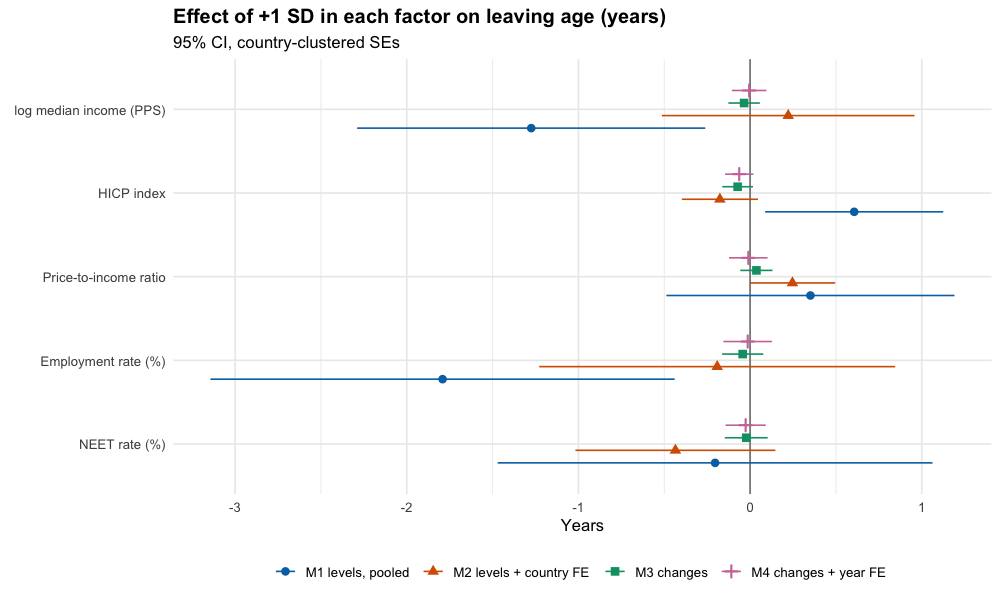

In [13]:
res$model <- factor(res$model, levels = unique(res$model))
res$factor <- factor(res$factor, levels = rev(plab))
p <- ggplot(res, aes(estimate, factor, colour = model, shape = model)) +
  geom_vline(xintercept = 0, colour = "grey50") +
  geom_pointrange(aes(xmin = lo, xmax = hi), position = position_dodge(width = .6)) +
  scale_colour_manual(values = c("#0072B2", "#D55E00", "#009E73", "#CC79A7"), name = NULL) +
  scale_shape_discrete(name = NULL) +
  labs(title = "Effect of +1 SD in each factor on leaving age (years)", subtitle = "95% CI, country-clustered SEs",
       x = "Years", y = NULL)
print(p); save_fig(p, "08_coef_plot.png", 10, 6)

The intervals are wide and straddle zero for nearly all factors once country differences or EU-wide shocks are removed (M2–M4); only M1 shows clear effects.

### Diagnostics (M2)

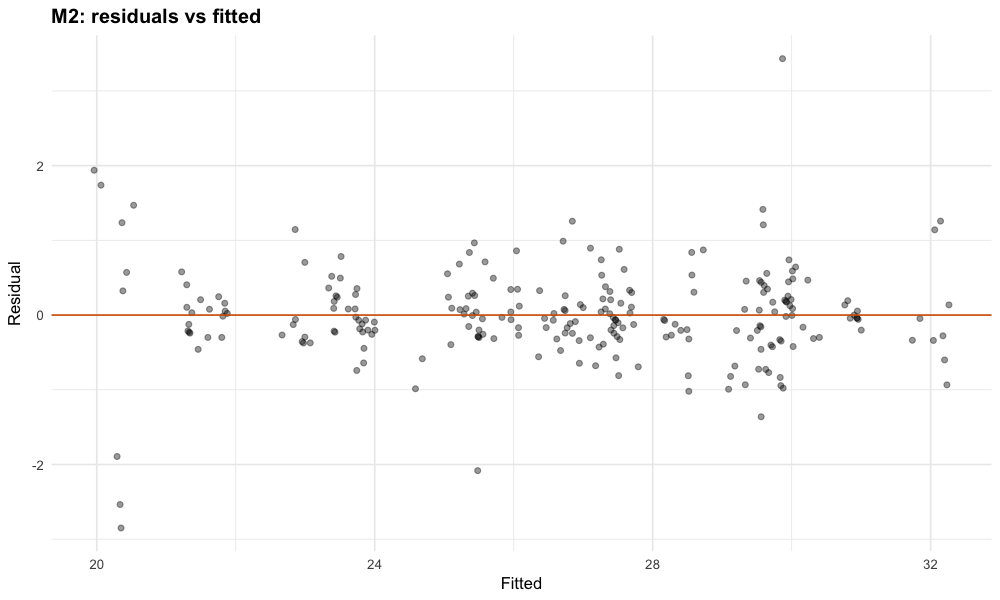

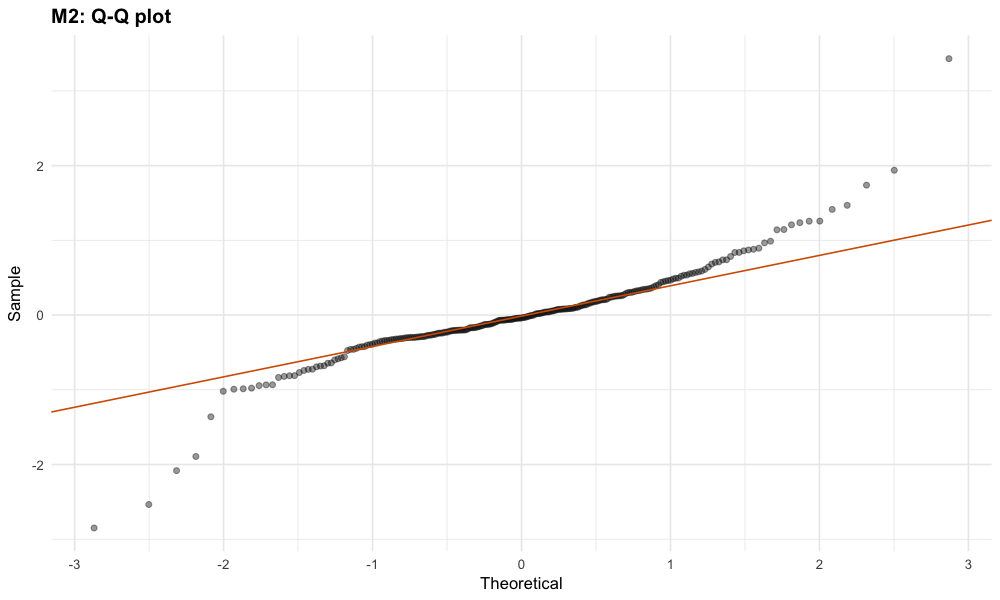

|    | fitted|  resid|  cook|country  | year|
|:---|------:|------:|-----:|:--------|----:|
|195 | 29.868|  3.432| 0.131|Portugal | 2021|
|239 | 20.350| -2.850| 0.082|Sweden   | 2020|
|238 | 20.336| -2.536| 0.065|Sweden   | 2019|
|243 | 19.962|  1.938| 0.048|Sweden   | 2024|
|11  | 25.482| -2.082| 0.045|Belgium  | 2017|
|27  | 29.561| -1.361| 0.044|Bulgaria | 2024|

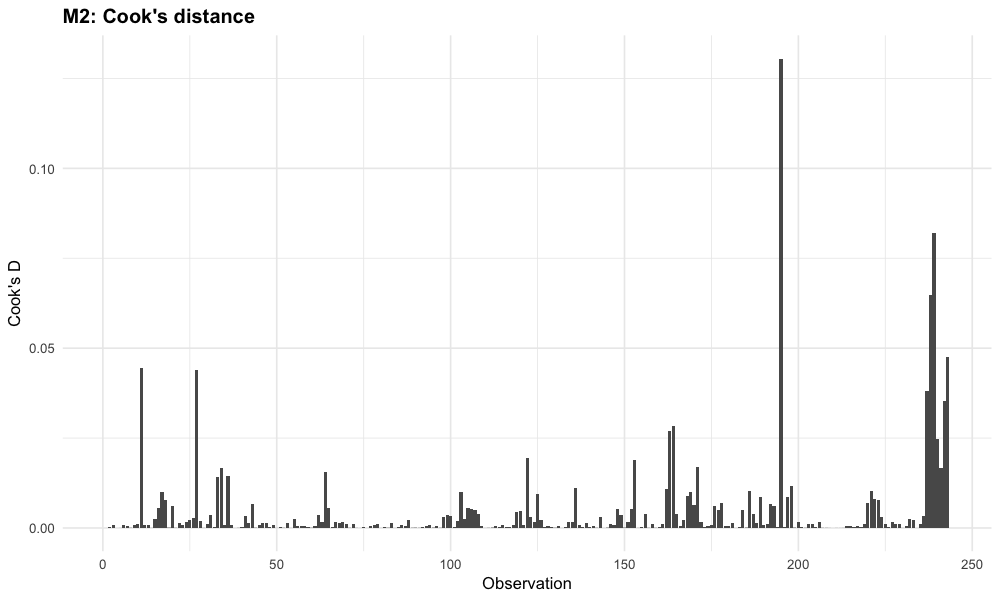

In [14]:
dg <- data.frame(fitted = fitted(m2), resid = resid(m2), cook = cooks.distance(m2), country = ds$country, year = ds$year)
a <- ggplot(dg, aes(fitted, resid)) + geom_point(alpha = .4) + geom_hline(yintercept = 0, colour = "#D55E00") +
  labs(title = "M2: residuals vs fitted", x = "Fitted", y = "Residual")
b <- ggplot(dg, aes(sample = resid)) + stat_qq(alpha = .4) + stat_qq_line(colour = "#D55E00") + labs(title = "M2: Q-Q plot", x = "Theoretical", y = "Sample")
cc <- ggplot(dg, aes(seq_along(cook), cook)) + geom_col() + labs(title = "M2: Cook's distance", x = "Observation", y = "Cook's D")
print(a); print(b); print(cc)
save_fig(a, "09a_resid_fitted.png", 7, 5); save_fig(b, "09b_qq.png", 7, 5); save_fig(cc, "09c_cooks.png", 8, 5)
tab(dg %>% arrange(desc(cook)) %>% head(6), 3)

Residuals are roughly centred with some tails; the most influential points are Portugal 2021 (Cook's D 0.13) and Sweden 2019–20, the known series breaks. No other observation is influential.

### Sensitivity: dropping 2020–21 and Sweden & Portugal

In [15]:
ds2 <- ds %>% filter(!year %in% c(2020, 2021)); dds2 <- dds %>% filter(!year %in% c(2020, 2021))
s1 <- coef_tab(lm(reformulate(c(zp, "factor(country)"), "leave_age"), ds2), ds2$country, "M2 excl. 2020-21", zp)
s2 <- coef_tab(lm(reformulate(c(zd, "year_f"), "d_leave_age"), dds2), dds2$country, "M4 excl. 2020-21", zd)
ds3 <- ds %>% filter(!(country %in% c("Sweden", "Portugal")))
s3 <- coef_tab(lm(reformulate(c(zp, "factor(country)"), "leave_age"), ds3), ds3$country, "M2 excl. Sweden & Portugal", zp)
tab(bind_rows(s1, s2, s3) %>% mutate(factor = plab[sub("z_(d_)?", "", term)]) %>% select(model, factor, estimate, se, p), 3)

|model                      |factor                  | estimate|    se|     p|
|:--------------------------|:-----------------------|--------:|-----:|-----:|
|M2 excl. 2020-21           |log median income (PPS) |   -0.001| 0.430| 0.999|
|M2 excl. 2020-21           |HICP index              |   -0.087| 0.121| 0.475|
|M2 excl. 2020-21           |Price-to-income ratio   |    0.189| 0.135| 0.173|
|M2 excl. 2020-21           |Employment rate (%)     |   -0.253| 0.554| 0.651|
|M2 excl. 2020-21           |NEET rate (%)           |   -0.513| 0.322| 0.122|
|M4 excl. 2020-21           |log median income (PPS) |    0.004| 0.052| 0.935|
|M4 excl. 2020-21           |HICP index              |   -0.036| 0.059| 0.546|
|M4 excl. 2020-21           |Price-to-income ratio   |   -0.039| 0.051| 0.451|
|M4 excl. 2020-21           |Employment rate (%)     |   -0.013| 0.054| 0.817|
|M4 excl. 2020-21           |NEET rate (%)           |   -0.006| 0.038| 0.872|
|M2 excl. Sweden & Portugal |log median income (PPS) |    0.123| 0.361| 0.735|
|M2 excl. Sweden & Portugal |HICP index              |   -0.209| 0.074| 0.009|
|M2 excl. Sweden & Portugal |Price-to-income ratio   |    0.226| 0.124| 0.082|
|M2 excl. Sweden & Portugal |Employment rate (%)     |   -0.032| 0.524| 0.952|
|M2 excl. Sweden & Portugal |NEET rate (%)           |   -0.361| 0.286| 0.219|

## 6. Conclusions

1. **Across the EU, levels differ by country, not by factor over time.** Between countries, a lower leaving age goes with higher employment and income (about −1.8 and −1.3 years per +1 SD), after controlling for the other factors.
2. **Within countries and over time, no factor is a reliable driver.** With country fixed effects the only borderline result is the price-to-income ratio (+0.25 years per +1 SD, p ≈ 0.05; +0.23, p = 0.08 without Sweden & Portugal). In changes, nothing is significant and R² ≤ 0.10. HICP is the only factor that becomes significant in a robustness check (−0.21, p = 0.009 excluding Sweden & Portugal), but its sign is opposite to its pooled effect, so it is not a stable driver.
3. **Employment and NEET are hard to separate** (r = −0.78); NEET has no independent effect once employment is in the model.
4. **Caveats.** Only 9 years and 27 countries; association, not causation; countries are unweighted; the leaving-age series have breaks (Sweden 2018–20, Portugal 2021); HICP is a general price index, not a measure of young people's living costs; slow-moving cultural and institutional factors (family norms, rental market, student housing) are absorbed by country fixed effects and cannot be studied with these data.